# Task 4 – Visual Analysis of Embeddings

Reproduce the qualitative analyses: t-SNE maps, confusion matrices, shirt ↔ T-shirt transitions, and recommendation grids.

## Context
Task 4 goes beyond labels and inspects the learned feature landscape. We use dimensionality reduction plots, an analysis of overlapping classes, a confusion matrix for the first ten classes, and a closer look at the transition between shirts and t shirts. It also requires evaluating the representation of higher level categories. This notebook reproduces each of those steps.

In [1]:
from pathlib import Path

import torch
import pandas as pd
from torch.utils.data import DataLoader

from fashion_metric import (
    CNET_HHD0_V44,
    evaluate_knn,
    extract_embeddings,
    plot_tsne_embeddings,
    plot_confusion_matrix,
    visualize_shirt_tshirt_transition,
    show_top3_recommendations_same_class,
)
from fashion_metric.config import DATA_PATH
from fashion_metric.data import build_all_datasets

In [2]:
DATASETS = build_all_datasets()
train_loader = DataLoader(DATASETS["train_dataset"], batch_size=32, shuffle=False)
main_test_loader = DataLoader(DATASETS["main_test_dataset"], batch_size=32, shuffle=False)
main_support_loader = DataLoader(DATASETS["main_support_dataset"], batch_size=32, shuffle=False)
merged_test_loader = DataLoader(DATASETS["merged_test_dataset"], batch_size=32, shuffle=False)
merged_support_loader = DataLoader(DATASETS["merged_support_dataset"], batch_size=32, shuffle=False)

In [4]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
EMBEDDING_WEIGHTS = Path("output/metric_learning/metric_model.pt")
model = CNET_HHD0_V44(num_classes=39, input_shape=(3, 60, 80))
if EMBEDDING_WEIGHTS.exists():
    state_dict = torch.load(EMBEDDING_WEIGHTS, map_location=DEVICE)
    model.load_state_dict(state_dict)
else:
    raise FileNotFoundError(f"Could not find weights at {EMBEDDING_WEIGHTS}. Train Task 2 or update the path.")
model.to(DEVICE)
model.eval()


CNET_HHD0_V44(
  (block1): Sequential(
    (0): Conv2d(3, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout(p=0.05, inplace=False)
  )
  (block2): Sequential(
    (0): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout(p=0.05, inplace=False)
  )
  (block3): Sequential(
    (0): Conv2d(512, 1024, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0,

In [5]:
label_df = pd.read_csv(DATA_PATH / "train.csv")
label_map = dict(label_df.drop_duplicates("articleTypeId")[ ["articleTypeId", "articleTypeName"] ].values)

In [6]:
category_df = pd.read_csv(DATA_PATH / "main_support.csv")
label_map_category = dict(category_df.drop_duplicates("categoryId")[ ["categoryId", "categoryName"] ].values)

main_support_cat_loader = DataLoader(DATASETS["main_support_dataset_cat"], batch_size=32, shuffle=False)
main_test_cat_loader = DataLoader(DATASETS["main_test_dataset_cat"], batch_size=32, shuffle=False)


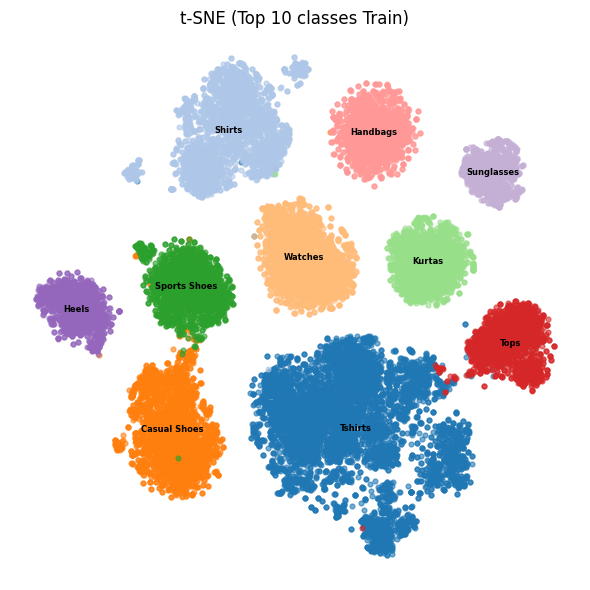

In [7]:
embeddings, labels = extract_embeddings(train_loader, model, embedding_dim=8192, device=DEVICE.type)
plot_tsne_embeddings(embeddings, labels, label_map, name="Train", num_class_show=10)

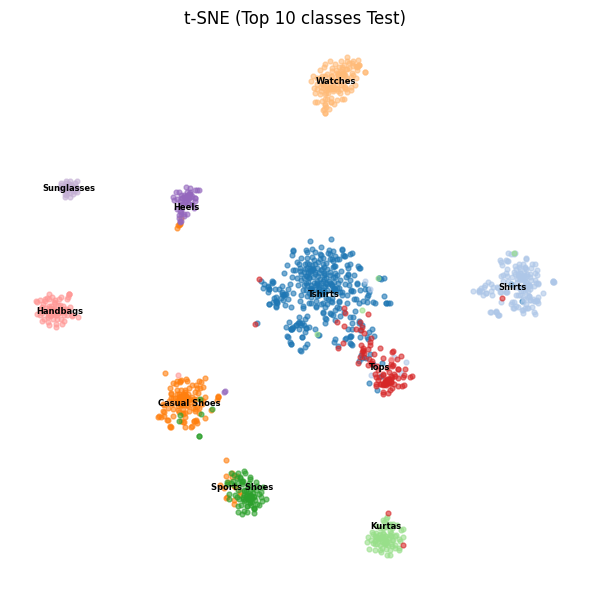

In [8]:
test_embeddings, test_labels = extract_embeddings(main_test_loader, model, embedding_dim=8192, device=DEVICE.type)
plot_tsne_embeddings(test_embeddings, test_labels, label_map, name="Test", num_class_show=10)


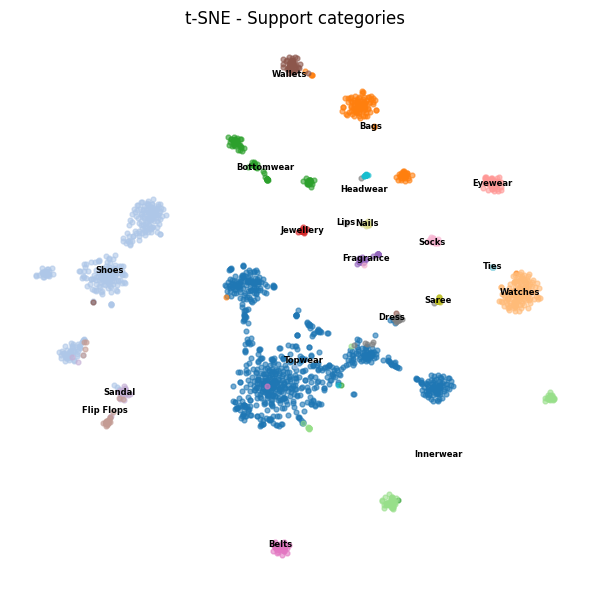

In [9]:
cat_support_embeddings, cat_support_labels = extract_embeddings(main_support_cat_loader, model, embedding_dim=8192, device=DEVICE.type)
plot_tsne_embeddings(cat_support_embeddings, cat_support_labels, label_map_category, name="Support categories")

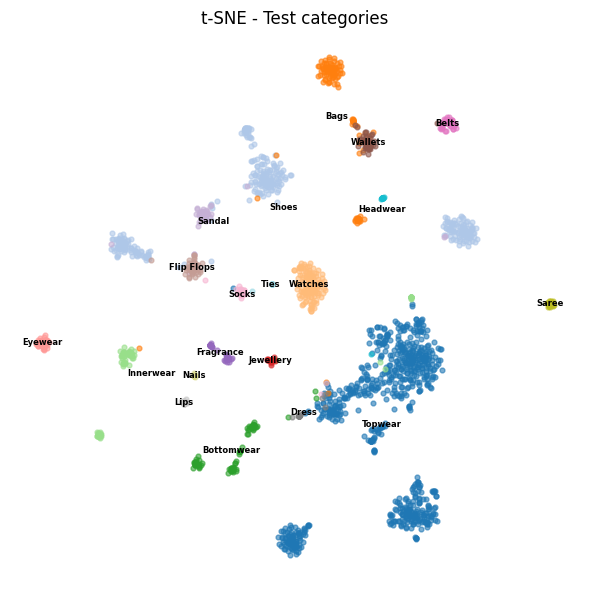

In [10]:
cat_test_embeddings, cat_test_labels = extract_embeddings(main_test_cat_loader, model, embedding_dim=8192, device=DEVICE.type)
plot_tsne_embeddings(cat_test_embeddings, cat_test_labels, label_map_category, name="Test categories")

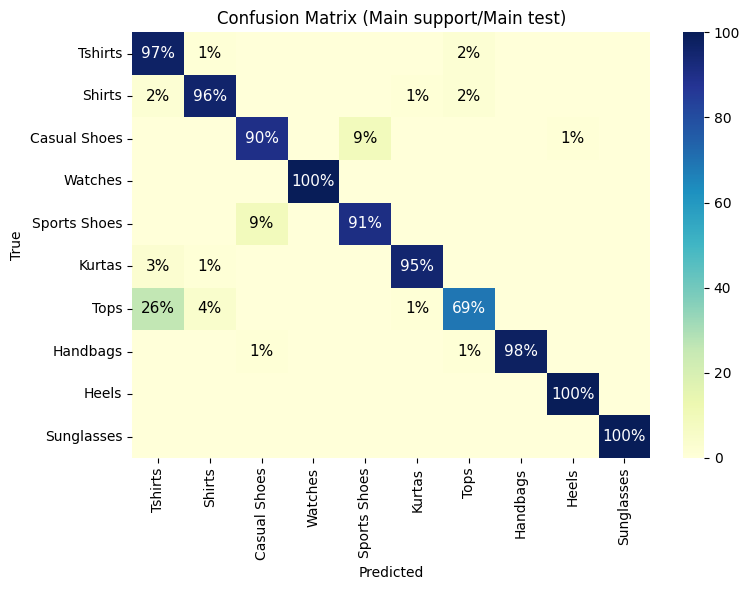

In [11]:
test_labels, predicted_labels = evaluate_knn(main_support_loader, main_test_loader, model, k=3, device=DEVICE.type)
plot_confusion_matrix(test_labels, predicted_labels, map=label_map, name="Main support/Main test", num_class_show=10)

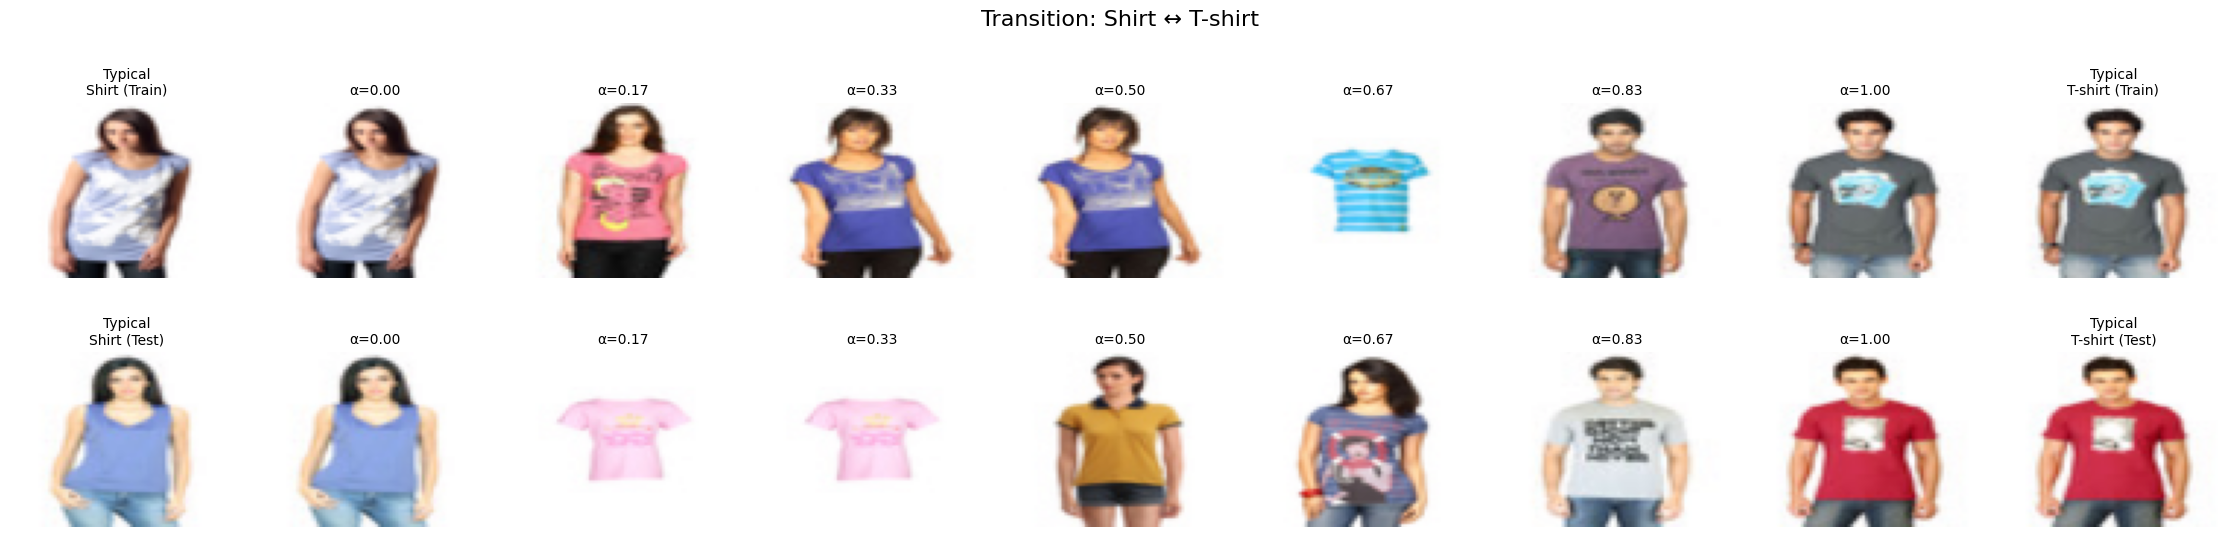

In [12]:
visualize_shirt_tshirt_transition(
    support_loader=main_support_loader,
    test_loader=main_test_loader,
    support_dataset=DATASETS["main_support_dataset"],
    test_dataset=DATASETS["main_test_dataset"],
    shirt_label=6,
    tshirt_label=0,
    model=model,
    n_steps=7,
    title="Transition: Shirt ↔ T-shirt",
    device=DEVICE.type,
)



In [16]:
show_top3_recommendations_same_class(
    model=model,
    test_loader=main_test_loader,
    support_loader=main_support_loader,
    test_dataset=DATASETS["main_test_dataset"],
    support_dataset=DATASETS["main_support_dataset"],
    label_map=label_map,
    n_samples=50,
    device=DEVICE.type,
    confidence_threshold=0.57,
)